In [1]:
# Install UCI REPO Library
!pip install -q ucimlrepo

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [5]:
# fetch data
adult_income = fetch_ucirepo(id=2)

In [ ]:
# Data
X = adult_income.data.features
y = adult_income.data.targets

# Concate Features and Target
df = pd.concat([X, y], axis=1)

# Show Top 5
df.head()

In [7]:
df.shape

(48842, 15)

In [ ]:
# Inspect metadata
adult_income.metadata

TASK 1


In [ ]:
##checking data indormation
df.info()

In [ ]:
#for checking thw missing values
df.isnull().sum()

In [ ]:
# only for showing variables that have missing values
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

In [ ]:
# Answer task 1 using this cell

df.info()

missing_values = df.isnull().sum()

print("\nVariables with missing values:")
print(missing_values[missing_values > 0])

TASK II

In [ ]:

for col in ["workclass", "occupation", "native-country"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Verify missing values
print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


In [16]:
missing_after = df.isnull().sum()
print(missing_after[missing_after > 0])

Series([], dtype: int64)


TASK III

In [17]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [19]:
# Check quantitative variables
quantitative_cols = df.select_dtypes(include="number").columns

print("Quantitative variables:")
print(quantitative_cols)

print("\nSummary:")
print(df[quantitative_cols].describe())

Quantitative variables:
Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='str')

Summary:
                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  48842.000000  4.884200e+04   48842.000000  48842.000000  48842.000000   
mean      38.643585  1.896641e+05      10.078089   1079.067626     87.502314   
std       13.710510  1.056040e+05       2.570973   7452.019058    403.004552   
min       17.000000  1.228500e+04       1.000000      0.000000      0.000000   
25%       28.000000  1.175505e+05       9.000000      0.000000      0.000000   
50%       37.000000  1.781445e+05      10.000000      0.000000      0.000000   
75%       48.000000  2.376420e+05      12.000000      0.000000      0.000000   
max       90.000000  1.490400e+06      16.000000  99999.000000   4356.000000   

       hours-per-week  
count    48842.000000  
mean        40.422382  
std         12.391444  
min          1.000000  
25%    

Based on the inspection of the quantitative variables, the dataset contains six quantitative variables: age, fnlwgt, education-num, capital-gain, capital-loss, and hours-per-week. The values were inspected using descriptive statistics, including minimum, maximum, mean, and standard deviation. Most of the values appear to be within reasonable ranges

PART II
task 1


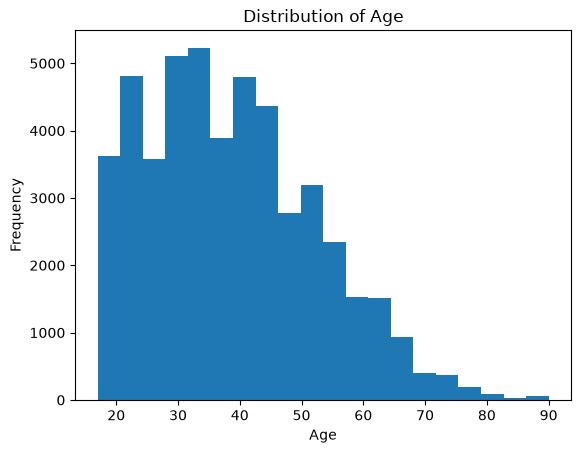

In [20]:
# Answer 1.1 - Histrogram
import matplotlib.pyplot as plt

plt.hist(df["age"], bins=20)
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Age")
plt.show()

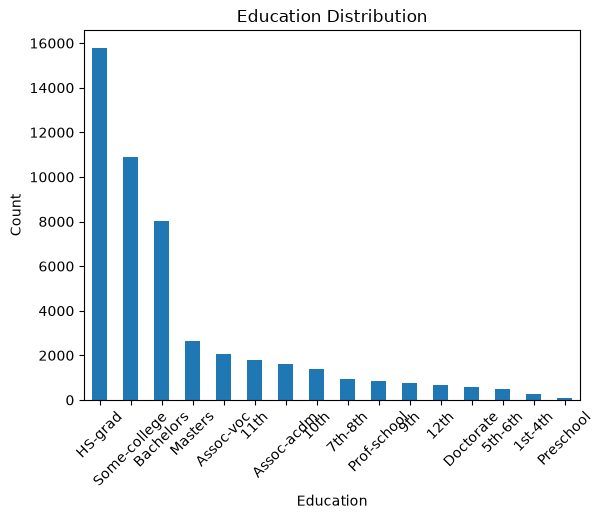

In [ ]:
# Answer 1.2 - Barchart
education_counts = df["education"].value_counts()

education_counts.plot(kind="bar")
plt.xlabel("Education")
plt.ylabel("Count")
plt.title("Education Distribution")
plt.xticks(rotation=45)
plt.show()

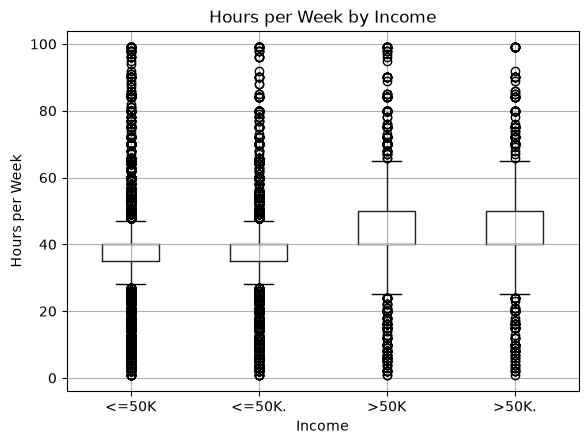

In [ ]:
# Answer 1.3 - Boxplot
df.boxplot(column="hours-per-week", by="income")

plt.xlabel("Income")
plt.ylabel("Hours per Week")
plt.title("Hours per Week by Income")
plt.suptitle("")
plt.show()

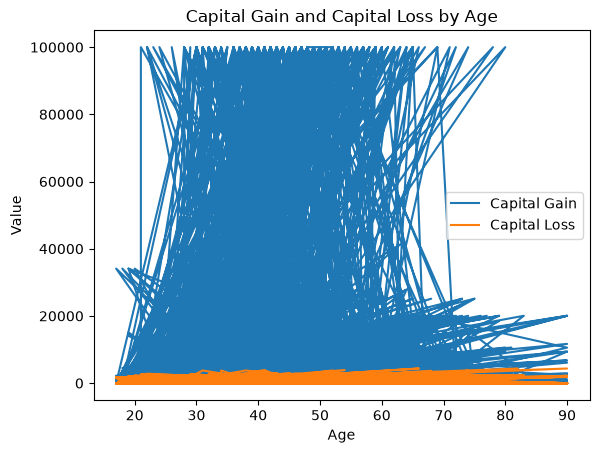

In [ ]:
# Answer 1.4 - Lineplot
plt.plot(df["age"], df["capital-gain"], label="Capital Gain")
plt.plot(df["age"], df["capital-loss"], label="Capital Loss")

plt.xlabel("Age")
plt.ylabel("Value")
plt.title("Capital Gain and Capital Loss by Age")
plt.legend()
plt.show()

PART II
Task 2

In [26]:
# 1. The 'age' variable shows a slightly right-skewed distribution,
#    with most observations concentrated around the adult age range.

In [27]:
# 2. If missing values were found in 'age', I would use median imputation
#    because it is suitable for numerical data and is less affected by outliers.

In [28]:
for income in df["income"].unique():
    data = df[df["income"] == income]["hours-per-week"]

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[(data < lower) | (data > upper)]

    print(income, ":", len(outliers), "outliers")

<=50K : 7809 outliers
>50K : 510 outliers
<=50K. : 3897 outliers
>50K. : 271 outliers


In [29]:
# 3. The <=50K category has 7809 outliers, >50K has 510 outliers,
#    <=50K. has 3897 outliers, and >50K. has 271 outliers.
#    The <=50K category has the most outliers.

PART III
task 1

In [30]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["sex"] = le.fit_transform(df["sex"])
df["income"] = le.fit_transform(df["income"])

print(df[["sex", "income"]].head())

   sex  income
0    1       0
1    1       0
2    1       0
3    1       0
4    0       0


PART IV
task 1

In [ ]:
corr = df[
    ["age", "education-num", "hours-per-week",
    "capital-gain", "capital-loss", "income"]
].corr()

print(corr)

                     age  education-num  hours-per-week  capital-gain  \
age             1.000000       0.030940        0.071558      0.077229   
education-num   0.030940       1.000000        0.143689      0.125146   
hours-per-week  0.071558       0.143689        1.000000      0.082157   
capital-gain    0.077229       0.125146        0.082157      1.000000   
capital-loss    0.056944       0.080972        0.054467     -0.031441   
income          0.205173       0.291074        0.198890      0.195755   

                capital-loss    income  
age                 0.056944  0.205173  
education-num       0.080972  0.291074  
hours-per-week      0.054467  0.198890  
capital-gain       -0.031441  0.195755  
capital-loss        1.000000  0.129771  
income              0.129771  1.000000  


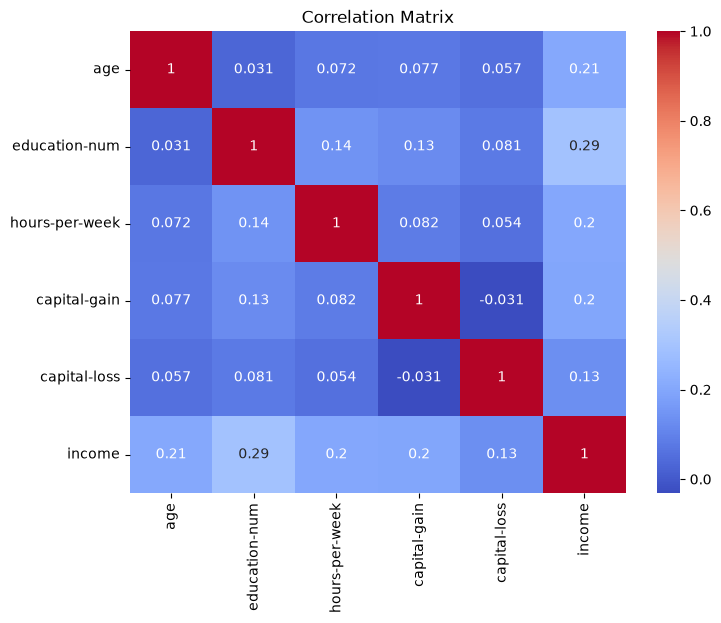

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

PART V

In [35]:
!pip install tensorflow

ERROR: Could not find a version that satisfies the requirement tensorflow (from versions: none)
ERROR: No matching distribution found for tensorflow


In [37]:
from sklearn.datasets import fetch_openml
import numpy as np
import matplotlib.pyplot as plt

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

x = mnist.data
y = mnist.target.astype(int)

# Use test set
x_test = x[60000:]
y_test = y[60000:]

# Reshape images
x_test = x_test.reshape(-1, 28, 28)

print("Test shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

Test shape: (10000, 28, 28)
Test labels shape: (10000,)


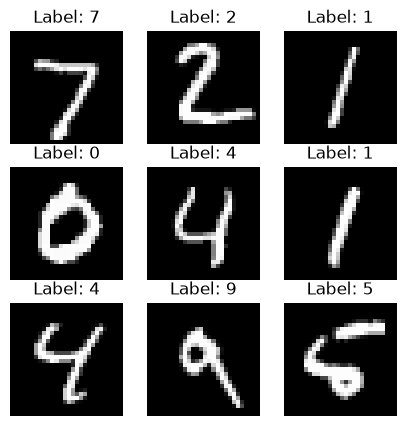

In [38]:
plt.figure(figsize=(5,5))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Label: {y_test[i]}")
    plt.axis("off")

plt.show()

PART V
task 1

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

x_test_32 = np.zeros((10000, 32, 32))

# Resize all images
for i in range(10000):
    img = Image.fromarray(x_test[i].astype(np.uint8))
    img = img.resize((32, 32))
    x_test_32[i] = np.array(img)

print("New shape:", x_test_32.shape)

New shape: (10000, 32, 32)


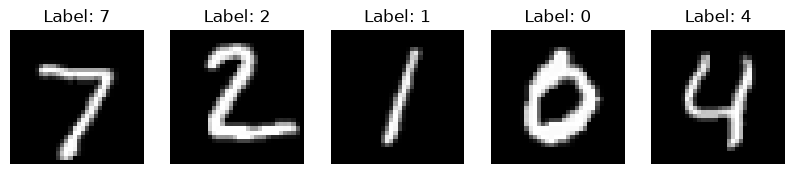

In [41]:
plt.figure(figsize=(10, 2))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test_32[i], cmap="gray")
    plt.title("Label: " + str(y_test[i]))
    plt.axis("off")

plt.show()

PART V 
task 1


In [ ]:
# normalazation
x_test_normalized = x_test_32 / 255

print("Minimum:", x_test_normalized.min())
print("Maximum:", x_test_normalized.max())

Minimum: 0.0
Maximum: 1.0


PART V 
task 3

In [ ]:
## into one dimensiona;l array
x_test_flat = x_test_normalized.reshape(10000, 1024)

print("Shape:", x_test_flat.shape)

Shape: (10000, 1024)
